In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [6]:
customers = pd.read_csv("FinTrust_Customers_Cleaned_Data.csv")
transactions = pd.read_csv("FinTrust_Transactions_Cleaned_Data.csv")

In [3]:
customers.head()

,Customer_ID,Customer_Name,Age,Gender,City,Customer_Segment,Account_Type,Tenure_Months,Digital_Engagement_Score,Monthly_Income_Band,Preferred_Channel,Account_Status
0,FT-C00001,Ibrahim Adeyemi,56,Male,Lagos,Premium,Savings,55,84.9,500k-999k,Mobile App,Active
1,FT-C00002,Yusuf Mohammed,46,Male,Kano,Everyday,Current,79,50.7,500k-999k,Mobile App,Active
2,FT-C00003,Emeka Adeyemi,32,Female,Port Harcourt,Everyday,Savings,43,56.1,1m+,Mobile App,Active
3,FT-C00004,David Williams,60,Female,Benin City,Premium,Premium,44,54.0,500k-999k,Mobile App,Dormant
4,FT-C00005,Blessing Adeyemi,25,Male,Kaduna,Premium,Savings,68,85.1,500k-999k,Mobile App,Active


In [7]:
customers.tail()

,Customer_ID,Customer_Name,Age,Gender,City,Customer_Segment,Account_Type,Tenure_Months,Digital_Engagement_Score,Monthly_Income_Band,Preferred_Channel,Account_Status
1495,FT-C01496,Grace Adeyemi,24,Male,Lagos,Everyday,Savings,35,76.0,250k-499k,Mobile App,Active
1496,FT-C01497,Zainab Adebayo,26,Male,Ibadan,Premium,Current,72,63.2,100k-249k,Mobile App,Active
1497,FT-C01498,Tunde Ojo,65,Male,Enugu,Student,Savings,66,93.1,250k-499k,Mobile App,Active
1498,FT-C01499,Samuel Adebayo,25,Male,Benin City,Everyday,Premium,6,88.8,100k-249k,Mobile App,Active
1499,FT-C01500,Blessing Adebayo,40,Male,Lagos,Student,Current,31,51.1,100k-249k,Web,Active


In [8]:
customers.shape

(1500, 12)

In [9]:
customers.describe()

,Age,Tenure_Months,Digital_Engagement_Score
count,1500.000000,1500.000000,1500.000000
mean,41.587333,49.858667,67.954000
std,13.733127,27.910990,17.555376
min,18.000000,1.000000,16.700000
25%,29.750000,26.000000,56.100000
50%,42.000000,51.000000,68.000000
75%,53.000000,74.000000,80.925000
max,65.000000,96.000000,100.000000


In [10]:
customers.dtypes

Customer_ID                  object
Customer_Name                object
Age                           int64
Gender                       object
City                         object
Customer_Segment             object
Account_Type                 object
Tenure_Months                 int64
Digital_Engagement_Score    float64
Monthly_Income_Band          object
Preferred_Channel            object
Account_Status               object
dtype: object

In [11]:
customers.info

<bound method DataFrame.info of      Customer_ID     Customer_Name  Age  Gender           City  \
0      FT-C00001   Ibrahim Adeyemi   56    Male          Lagos   
1      FT-C00002    Yusuf Mohammed   46    Male           Kano   
2      FT-C00003     Emeka Adeyemi   32  Female  Port Harcourt   
3      FT-C00004    David Williams   60  Female     Benin City   
4      FT-C00005  Blessing Adeyemi   25    Male         Kaduna   
...          ...               ...  ...     ...            ...   
1495   FT-C01496     Grace Adeyemi   24    Male          Lagos   
1496   FT-C01497    Zainab Adebayo   26    Male         Ibadan   
1497   FT-C01498         Tunde Ojo   65    Male          Enugu   
1498   FT-C01499    Samuel Adebayo   25    Male     Benin City   
1499   FT-C01500  Blessing Adebayo   40    Male          Lagos   

     Customer_Segment Account_Type  Tenure_Months  Digital_Engagement_Score  \
0             Premium      Savings             55                      84.9   
1            Ever

In [12]:
print(customers.isnull().sum())

Customer_ID                 0
Customer_Name               0
Age                         0
Gender                      0
City                        0
Customer_Segment            0
Account_Type                0
Tenure_Months               0
Digital_Engagement_Score    0
Monthly_Income_Band         0
Preferred_Channel           0
Account_Status              0
dtype: int64


In [13]:
transactions.head()

,Transaction_ID,Customer_ID,Transaction_DateTime,Transaction_Type,Amount_NGN,Channel,Device_Type,Location,International_Transaction,Transaction_Status,Risk_Review_Flag
0,FT-T000001,FT-C01135,01/01/2026 00:00,Card Purchase,5923.80,Mobile App,Android,Enugu,No,Reversed,Yes
1,FT-T000002,FT-C00428,01/01/2026 00:10,Cash Withdrawal,11681.12,ATM,Android,Kaduna,No,Successful,Yes
2,FT-T000003,FT-C00469,01/01/2026 00:21,Transfer,571.91,ATM,POS Terminal,Kano,No,Successful,No
3,FT-T000004,FT-C01015,01/01/2026 00:32,Deposit,105367.52,Mobile App,Web Browser,Abuja,No,Successful,No
4,FT-T000005,FT-C00870,01/01/2026 00:43,Cash Withdrawal,3049.06,Mobile App,POS Terminal,Abuja,No,Successful,No


In [14]:
transactions.tail()

,Transaction_ID,Customer_ID,Transaction_DateTime,Transaction_Type,Amount_NGN,Channel,Device_Type,Location,International_Transaction,Transaction_Status,Risk_Review_Flag
11995,FT-T011996,FT-C01367,3/31/2026 23:16,Card Purchase,9336.19,Web,Web Browser,Lagos,No,Successful,No
11996,FT-T011997,FT-C00395,3/31/2026 23:27,Airtime/Data,16198.02,Mobile App,iOS,Ibadan,No,Successful,No
11997,FT-T011998,FT-C00484,3/31/2026 23:38,Card Purchase,62448.87,Mobile App,ATM Terminal,Lagos,No,Successful,No
11998,FT-T011999,FT-C00666,3/31/2026 23:49,Card Purchase,696.48,Mobile App,Android,Benin City,No,Successful,No
11999,FT-T012000,FT-C00456,3/31/2026 23:59,Cash Withdrawal,26888.41,POS,iOS,Kaduna,No,Successful,Yes


In [15]:
transactions.describe()

,Amount_NGN
count,12000.000000
mean,46706.446238
std,86028.715234
min,100.170000
25%,2192.220000
50%,10305.935000
75%,48484.475000
max,693454.450000


In [16]:
transactions.shape

(12000, 11)

In [17]:
transactions.dtypes

Transaction_ID                object
Customer_ID                   object
Transaction_DateTime          object
Transaction_Type              object
Amount_NGN                   float64
Channel                       object
Device_Type                   object
Location                      object
International_Transaction     object
Transaction_Status            object
Risk_Review_Flag              object
dtype: object

In [18]:
transactions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12000 entries, 0 to 11999
Data columns (total 11 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Transaction_ID             12000 non-null  object 
 1   Customer_ID                12000 non-null  object 
 2   Transaction_DateTime       12000 non-null  object 
 3   Transaction_Type           12000 non-null  object 
 4   Amount_NGN                 12000 non-null  float64
 5   Channel                    12000 non-null  object 
 6   Device_Type                12000 non-null  object 
 7   Location                   12000 non-null  object 
 8   International_Transaction  12000 non-null  object 
 9   Transaction_Status         12000 non-null  object 
 10  Risk_Review_Flag           12000 non-null  object 
dtypes: float64(1), object(10)
memory usage: 1.0+ MB


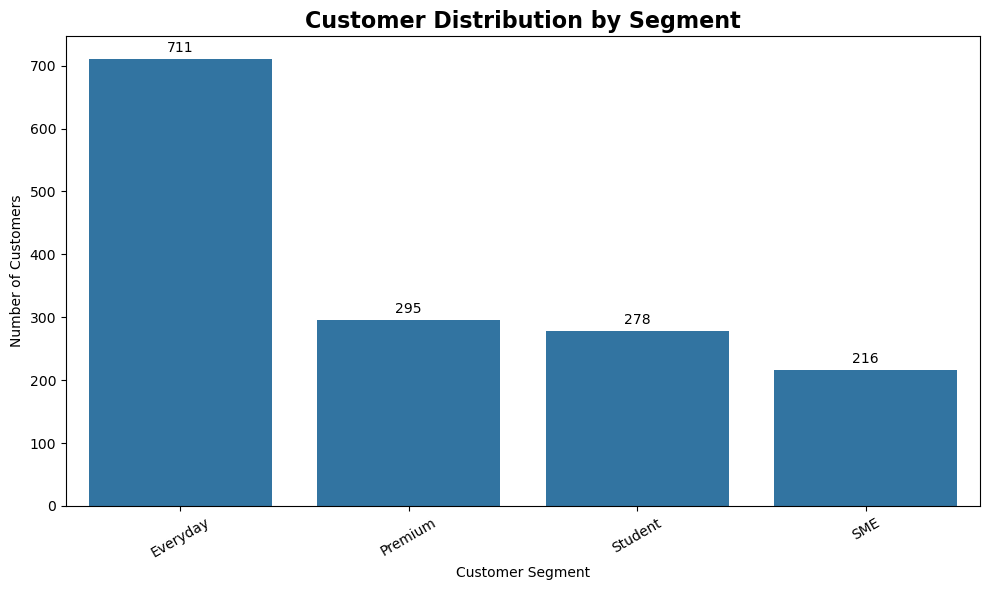

In [19]:
segment_analysis = (
    customers["Customer_Segment"]
    .value_counts()
    .reset_index()
)

segment_analysis.columns = ["Customer_Segment", "Customer_Count"]

plt.figure(figsize=(10, 6))
ax = sns.barplot(
    data=segment_analysis,
    x="Customer_Segment",
    y="Customer_Count"
)

plt.title("Customer Distribution by Segment", fontsize=16, fontweight="bold")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=30)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

What does the visual show?
The chart shows the distribution of FinTrust customers across four customer segments. The Everyday segment has the largest customer base with 711 customers, followed by Premium with 295, Student with 278, and SME with 216.

Why is it important?
Understanding the composition of the customer base helps FinTrust identify which customer groups represent the largest share of its customers. This can support decisions around marketing, customer engagement, product development and resource allocation.

Business insight:
The Everyday segment represents the largest customer group, accounting for approximately 47.4% of the 1,500 customers. Premium represents about 19.7%, Student about 18.5%, and SME about 14.4%. This shows that the customer base is concentrated in the Everyday segment, while the other three segments have considerably smaller populations.

Recommendation:
FinTrust could investigate whether transaction activity and transaction value are also concentrated in the Everyday segment. Comparing customer numbers with transaction behaviour would help determine whether the largest customer segment is also generating the greatest level of business activity.

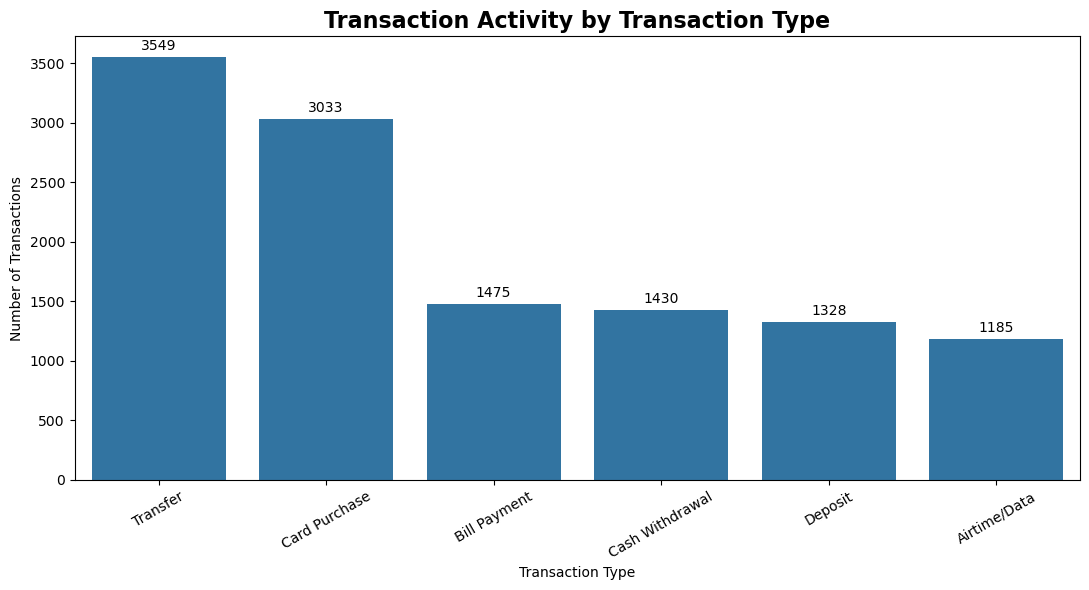

,Transaction_Type,Transaction_Count,Total_Value,Average_Value
5,Transfer,3549,2.379167e+08,67037.672699
2,Card Purchase,3033,8.586341e+07,28309.730887
1,Bill Payment,1475,2.816365e+07,19093.998312
3,Cash Withdrawal,1430,6.777236e+07,47393.260217
4,Deposit,1328,1.309851e+08,98633.328200
0,Airtime/Data,1185,9.776171e+06,8249.933494


In [20]:
type_analysis = (
    transactions.groupby("Transaction_Type")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Value=("Amount_NGN", "sum"),
        Average_Value=("Amount_NGN", "mean")
    )
    .reset_index()
    .sort_values("Transaction_Count", ascending=False)
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=type_analysis,
    x="Transaction_Type",
    y="Transaction_Count"
)

plt.title("Transaction Activity by Transaction Type",
          fontsize=16, fontweight="bold")
plt.xlabel("Transaction Type")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

type_analysis

What does the visual show?
The chart shows the volume of transactions across the different transaction types recorded by FinTrust.

Key finding:
Transfer is the most frequently recorded transaction type, with 3,549 transactions, followed by Card Purchase with 3,033 transactions. Airtime/Data has the lowest transaction volume, with 1,185 transactions.

Business insight:
The difference in transaction volumes suggests that customers use FinTrust's services more frequently for transfers and card purchases than for the other transaction types. This could indicate that these services are particularly important parts of customers' day-to-day banking activity.

Business implication:
FinTrust could monitor the performance and reliability of high-volume transaction services such as transfers and card purchases. However, transaction volume alone does not tell us which transaction type generates the most money

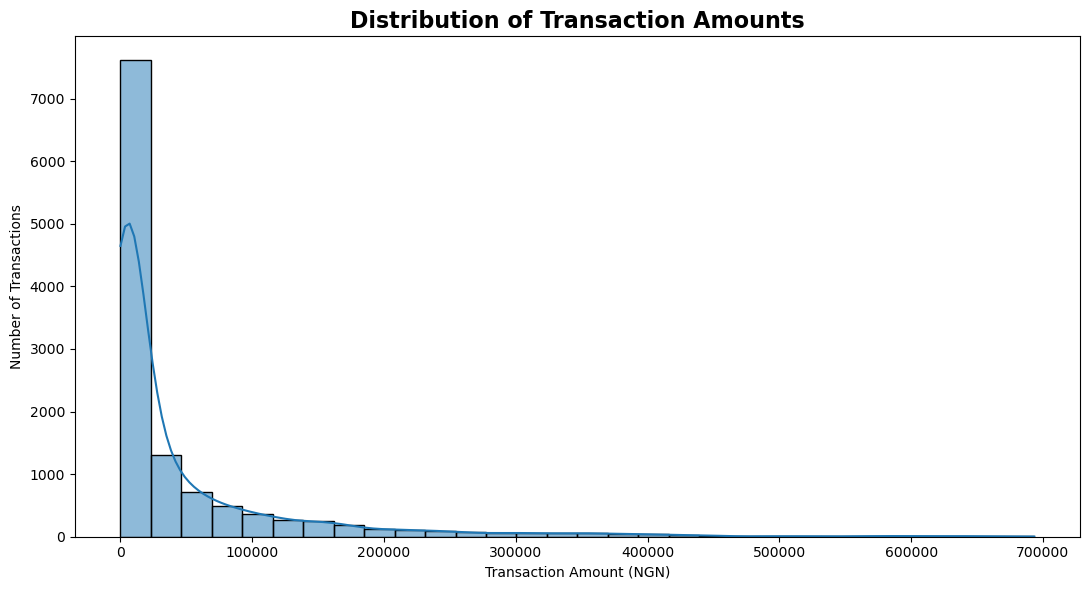

In [21]:
plt.figure(figsize=(11, 6))

sns.histplot(
    transactions["Amount_NGN"].dropna(),
    bins=30,
    kde=True
)

plt.title("Distribution of Transaction Amounts",
          fontsize=16, fontweight="bold")
plt.xlabel("Transaction Amount (NGN)")
plt.ylabel("Number of Transactions")

plt.tight_layout()
plt.show()

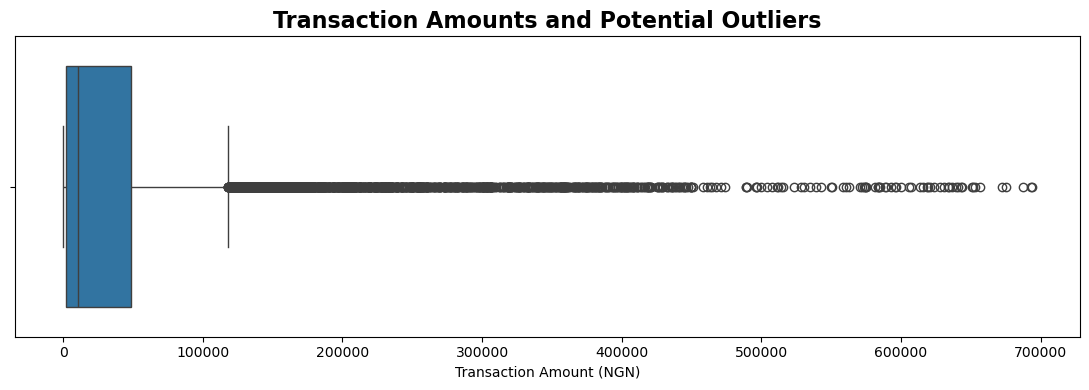

In [22]:
plt.figure(figsize=(11, 4))

sns.boxplot(
    x=transactions["Amount_NGN"].dropna()
)

plt.title("Transaction Amounts and Potential Outliers",
          fontsize=16, fontweight="bold")
plt.xlabel("Transaction Amount (NGN)")

plt.tight_layout()
plt.show()

What does it show?
The histogram shows how transaction amounts are distributed, while the box plot highlights unusually high or low observations.

Why is it important?
Transaction amounts can be heavily affected by extreme values.

Business insight:
Very high-value transactions may represent genuine customer activity, so potential outliers should be investigated rather than automatically removed.

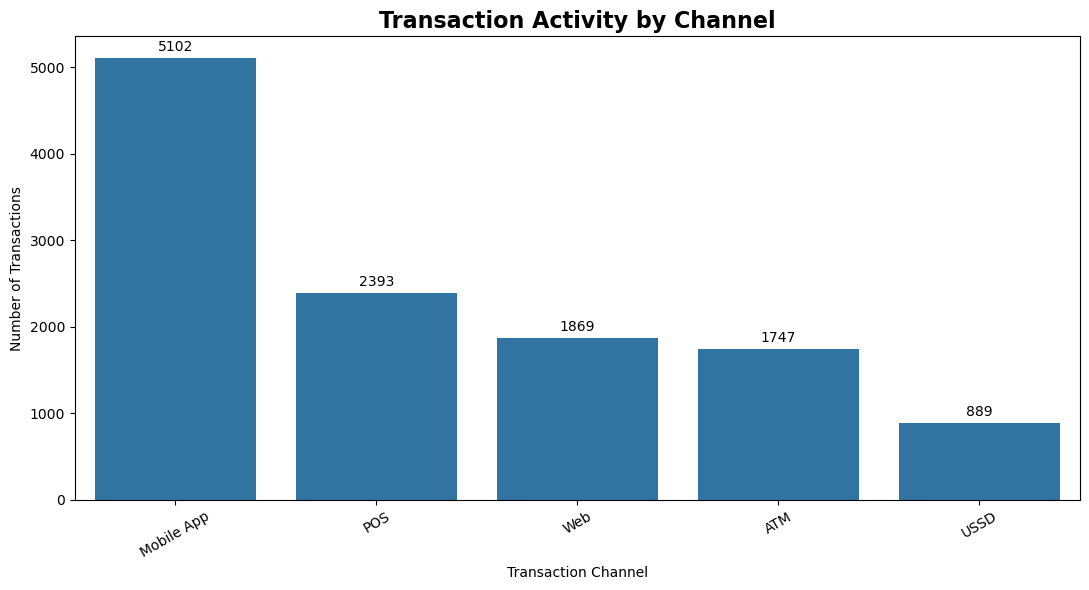

,Channel,Transaction_Count,Total_Value,Average_Value
1,Mobile App,5102,2.401044e+08,47060.832064
2,POS,2393,1.043467e+08,43604.964994
4,Web,1869,8.932500e+07,47792.937368
0,ATM,1747,8.394235e+07,48049.430011
3,USSD,889,4.275895e+07,48097.811316


In [23]:
channel_analysis = (
    transactions.groupby("Channel")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Value=("Amount_NGN", "sum"),
        Average_Value=("Amount_NGN", "mean")
    )
    .reset_index()
    .sort_values("Transaction_Count", ascending=False)
)

plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=channel_analysis,
    x="Channel",
    y="Transaction_Count"
)

plt.title("Transaction Activity by Channel",
          fontsize=16, fontweight="bold")
plt.xlabel("Transaction Channel")
plt.ylabel("Number of Transactions")
plt.xticks(rotation=30)

for container in ax.containers:
    ax.bar_label(container, fmt="%d", padding=3)

plt.tight_layout()
plt.show()

channel_analysis

Business Insight: Mobile App is the dominant transaction channel, recording 5,102 transactions and approximately ₦240.1 million in total transaction value. POS follows with 2,393 transactions and approximately ₦104.3 million. Although USSD has the lowest transaction volume, it records the highest average transaction value of approximately ₦48,098 per transaction. This indicates that channel popularity and transaction value do not necessarily follow the same pattern. FinTrust can use these findings to monitor high-volume digital channels while investigating the transaction types and customer behaviours associated with higher-value channels.

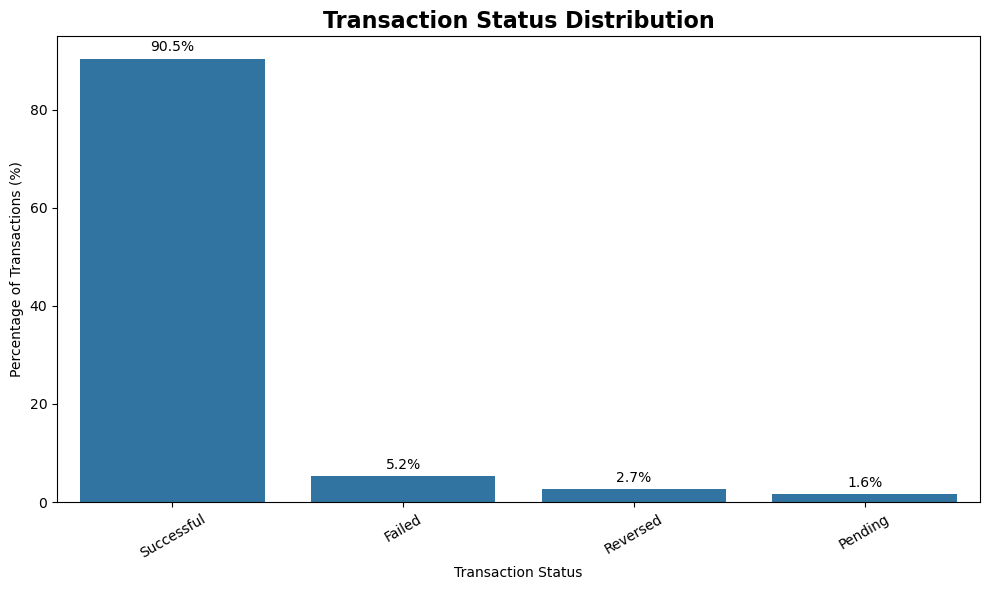

In [24]:
status_analysis = (
    transactions["Transaction_Status"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
    .reset_index()
)

status_analysis.columns = ["Transaction_Status", "Percentage"]

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=status_analysis,
    x="Transaction_Status",
    y="Percentage"
)

plt.title("Transaction Status Distribution",
          fontsize=16, fontweight="bold")
plt.xlabel("Transaction Status")
plt.ylabel("Percentage of Transactions (%)")
plt.xticks(rotation=30)

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

What does it show?
The percentage of transactions in each status category.

Why is it important?
It provides a clearer measure of transaction performance than raw counts alone.

Business Insight: The majority of FinTrust transactions were successful, accounting for 90.5% of all transactions. Failed transactions represented 5.2%, while 2.7% were reversed and 1.6% remained pending. Although successful transactions make up the largest proportion, the unsuccessful, reversed and pending transactions provide an opportunity for further investigation. FinTrust could analyse these transactions by channel, transaction type and customer segment to identify patterns that may help improve transaction completion and reduce failed or unresolved transactions.

In [25]:
risk_analysis = pd.crosstab(
    transactions["International_Transaction"],
    transactions["Risk_Review_Flag"],
    normalize="index"
).mul(100).round(2)

risk_analysis

Risk_Review_Flag,No,Yes
International_Transaction,,
No,81.12,18.88
Yes,63.12,36.88


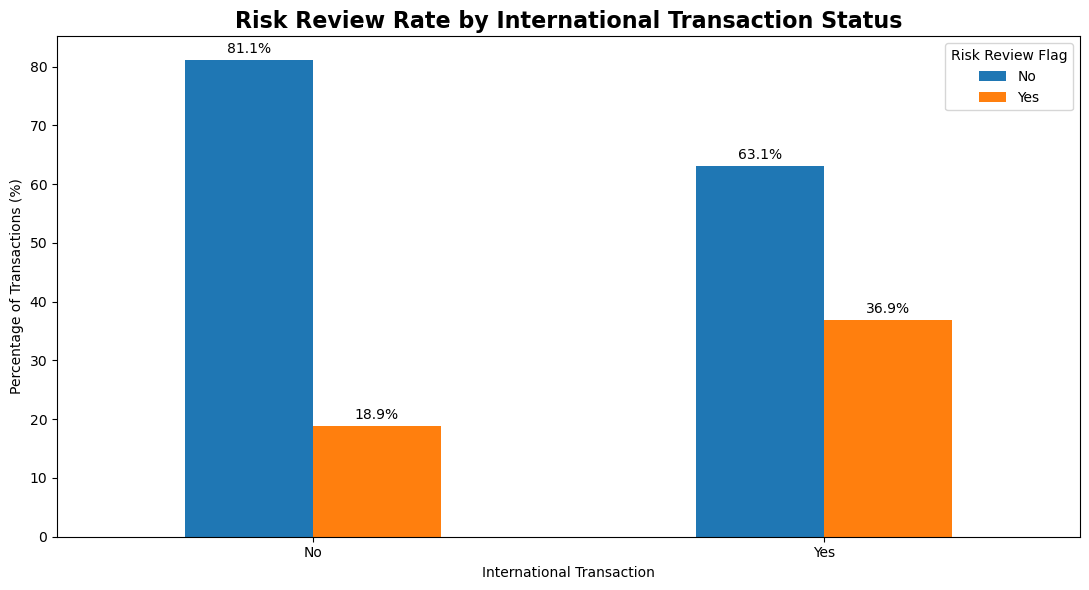

In [26]:
ax = risk_analysis.plot(
    kind="bar",
    figsize=(11, 6)
)

plt.title("Risk Review Rate by International Transaction Status",
          fontsize=16, fontweight="bold")
plt.xlabel("International Transaction")
plt.ylabel("Percentage of Transactions (%)")
plt.xticks(rotation=0)
plt.legend(title="Risk Review Flag")

for container in ax.containers:
    ax.bar_label(container, fmt="%.1f%%", padding=3)

plt.tight_layout()
plt.show()

What does it show?
It compares risk-review patterns between international and non-international transactions.

Why is it important?
It helps identify whether risk-review activity differs between these transaction groups.

Business insight:
 International transaction status looks like a meaningful risk signal. Worth checking whether this correlates with fraud outcomes (not just review flags) if flagged international transactions turn out fraudulent at a similar elevated rate, this variable could be a strong feature for a fraud model or a trigger for tighter automated screening rules on cross-border payments. If instead most flagged international transactions turn out legitimate, it may suggest the current rule is overly broad and generating unnecessary review workload (false positives), which is worth tuning to cut down on manual review costs.

In [27]:
df = transactions.merge(
    customers,
    on="Customer_ID",
    how="left"
)

segment_value = (
    df.groupby("Customer_Segment")
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Transaction_Value=("Amount_NGN", "sum"),
        Average_Transaction_Value=("Amount_NGN", "mean")
    )
    .reset_index()
    .sort_values("Total_Transaction_Value", ascending=False)
)

segment_value

,Customer_Segment,Transaction_Count,Total_Transaction_Value,Average_Transaction_Value
0,Everyday,5644,2.614589e+08,46325.110027
1,Premium,2361,1.077512e+08,45637.948251
3,Student,2289,1.074759e+08,46953.196300
2,SME,1706,8.379137e+07,49115.692679


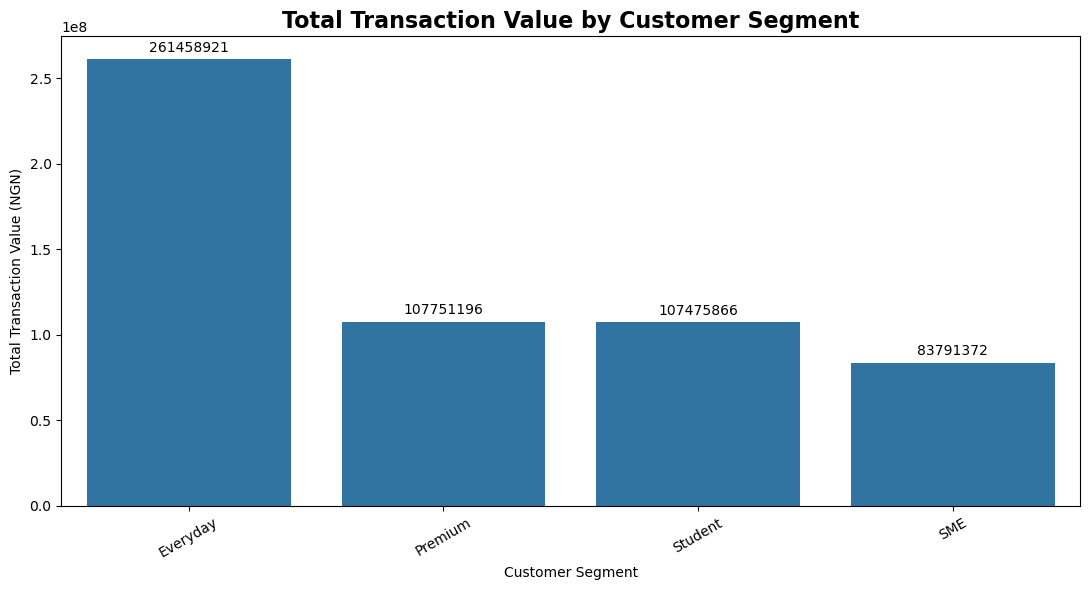

In [28]:
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    data=segment_value,
    x="Customer_Segment",
    y="Total_Transaction_Value"
)

plt.title("Total Transaction Value by Customer Segment",
          fontsize=16, fontweight="bold")
plt.xlabel("Customer Segment")
plt.ylabel("Total Transaction Value (NGN)")
plt.xticks(rotation=30)

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.0f",
        padding=3
    )

plt.tight_layout()
plt.show()

What does it show?
It compares the total monetary value of transactions associated with each customer segment.

Why is it important?
Customer numbers alone don't tell us how much transaction value each segment contributes.

Business insight:
Everyday users are the core revenue driver by volume, so retention and engagement strategies (fee structures, loyalty perks, fraud-monitoring priority) should weight this segment heavily losing even a small share of Everyday users likely hurts total transaction value more than losing an entire smaller segment. Meanwhile, Premium and Student are nearly tied (~₦107.5M each), which is worth a second look: if Premium customers are expected to transact at higher value per user, a similar total to Student could signal an underpenetrated or underperforming premium tier worth investigating is it low headcount, low usage, or pricing friction? SME sits lowest, suggesting either a small customer base or an untapped growth opportunity if SME transaction sizes are typically larger per transaction.

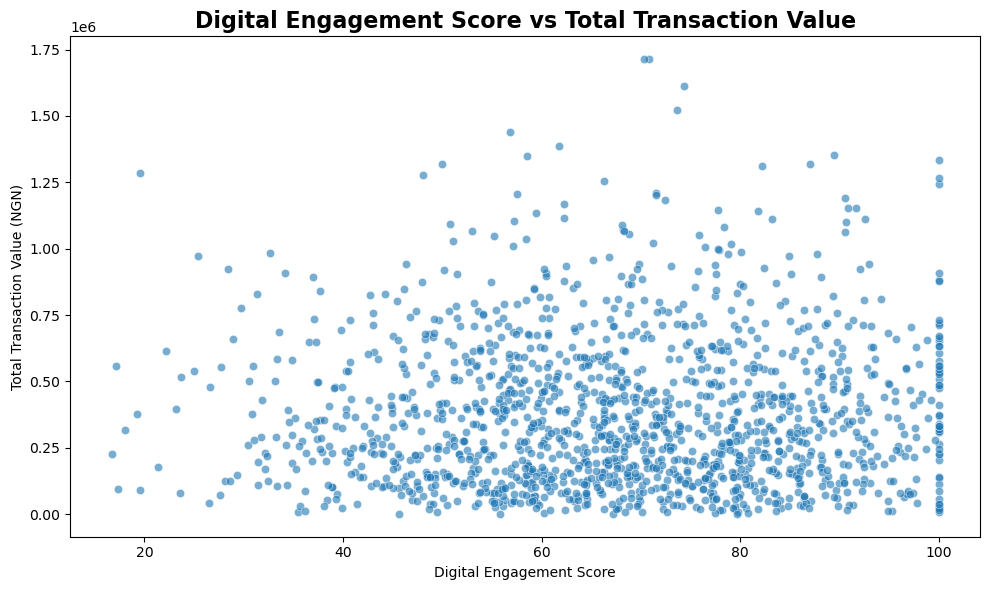

In [29]:
customer_activity = (
    df.groupby(["Customer_ID", "Digital_Engagement_Score"])
    .agg(
        Transaction_Count=("Transaction_ID", "count"),
        Total_Transaction_Value=("Amount_NGN", "sum")
    )
    .reset_index()
)

plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=customer_activity,
    x="Digital_Engagement_Score",
    y="Total_Transaction_Value",
    alpha=0.6
)

plt.title(
    "Digital Engagement Score vs Total Transaction Value",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Digital Engagement Score")
plt.ylabel("Total Transaction Value (NGN)")

plt.tight_layout()
plt.show()

What does it show?
Each point represents a customer and compares their digital engagement score with their total transaction value.

Why is it important?
It explores whether more digitally engaged customers also tend to have higher transaction values.

Business insight:
Digital engagement score alone isn't a reliable predictor of transaction value, so it shouldn't be used in isolation to prioritize high-value customers for marketing or retention spend. This suggests engagement (app opens, logins, feature usage) and monetary value are somewhat decoupled a customer can be highly "engaged" without transacting much, and vice versa. Worth investigating what engagement score is actually measuring (activity vs. spend intent) and pairing it with other features (segment, tenure, product mix) before using it in any scoring or targeting model. If you're building a predictive model for transaction value, this chart is a signal that engagement score alone will have weak predictive power — check its correlation coefficient to confirm.